In [1]:
import pandas as pd
dataset=pd.read_csv("insurance_pre.csv")

In [2]:
dataset=pd.get_dummies(dataset,drop_first=True)
dataset.columns

Index(['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes'], dtype='str')

In [3]:
independent=dataset[['age', 'bmi', 'children', 'sex_male', 'smoker_yes']]
dependent=dataset[["charges"]]
independent

,age,bmi,children,sex_male,smoker_yes
0,19,27.900,0,False,True
1,18,33.770,1,True,False
2,28,33.000,3,True,False
3,33,22.705,0,True,False
4,32,28.880,0,True,False
...,...,...,...,...,...
1333,50,30.970,3,True,False
1334,18,31.920,0,False,False
1335,18,36.850,0,False,False
1336,21,25.800,0,False,False


In [4]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent, dependent, test_size=0.30,random_state=0)


In [5]:
from sklearn.preprocessing import StandardScaler # here preprocessing is used to preprocess the train data to get better R2 value 
sc=StandardScaler() # This is preprocessor imported class.
X_train=sc.fit_transform(X_train) # Here need to transform train value to the decimal format
X_test=sc.transform(X_test)
X_train

array([[-1.5330973 , -0.40713453, -0.89833872, -0.97676557, -0.50466988],
       [-0.03364163,  0.32855417, -0.89833872, -0.97676557, -0.50466988],
       [ 0.89459283,  2.56690911,  3.25603402, -0.97676557, -0.50466988],
       ...,
       [ 0.03776102, -0.91016269, -0.89833872,  1.02378711, -0.50466988],
       [-1.46169465,  0.76659782, -0.89833872,  1.02378711, -0.50466988],
       [-0.46205754, -1.96596021, -0.06746417, -0.97676557, -0.50466988]],
      shape=(936, 5))

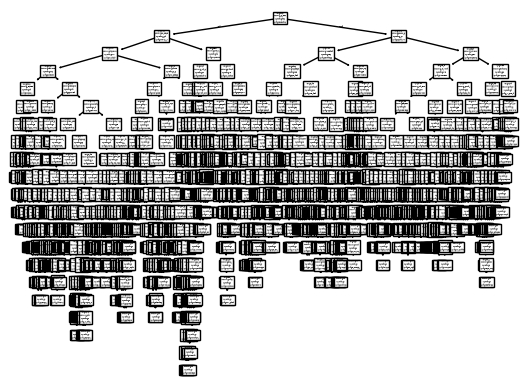

0.7074296524369417

In [14]:
#https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
from sklearn.tree import DecisionTreeRegressor # this is the procedure for the decision tree
regressor=DecisionTreeRegressor(criterion='poisson', splitter='best', max_features='sqrt', random_state=42) # to get the suitable model we can pass the parameters (squared_error,absolute_error,poisson)
regressor=regressor.fit(X_train,y_train)

import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(regressor)
plt.show()

y_pred=regressor.predict(X_test)
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)
r_score

In [11]:
import pickle
filename="finalized_model_Mul_linear.sav"
pickle.dump(regressor,open(filename,'wb'))

In [36]:
loaded_model=pickle.load(open("finalized_model_Mul_linear.sav",'rb'))
result=loaded_model.predict([[1000,2000,3000,1,0]])

In [37]:
result

array([16589.18908958])